# Analysing Crime in Mumbai — full pipeline in Python
Hotspots, common offences and trends across five police regions, 2013–2022.

**Pipeline:** raw files → cleaning → tidy (long) tables → analysis tables → charts → validation → Excel export.

Sources: Praja Foundation (2023), *State of Policing and Law and Order in Mumbai* (RTI figures from
Mumbai Police) and the Mumbai Police annual crime review 2023 (via OpenCity).

## 0. Setup
In Google Colab: upload `mumbai_crime_project.zip`, then run `!unzip -o mumbai_crime_project.zip` and
`%cd mumbai_crime_project` in a cell before this one.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path("data/raw")
CLEAN = Path("data/cleaned"); CLEAN.mkdir(parents=True, exist_ok=True)
OUT = Path("outputs");        OUT.mkdir(exist_ok=True)
FIG = OUT / "charts";         FIG.mkdir(exist_ok=True)

pd.set_option("display.width", 160, "display.max_columns", 20)

## 1. Load the raw files and look at what is wrong with them

In [2]:
ipc_raw   = pd.read_csv(RAW / "MumbaiPolice_IPC_Crimes_2022-2023.csv", dtype=str)
cyber_raw = pd.read_csv(RAW / "MumbaiPolice_CyberCrimes_2023.csv", dtype=str)   # dtype=str keeps S No. "8.10" from becoming 8.1
women_raw = pd.read_csv(RAW / "MumbaiPolice_CrimesAgainstWomen_2022-2023.csv", dtype=str)

for name, df in [("IPC", ipc_raw), ("Cyber", cyber_raw), ("Women", women_raw)]:
    print(f"\n--- {name}: {df.shape[0]} rows x {df.shape[1]} cols | missing cells: {int(df.isna().sum().sum())}")
    print(df.head(4).to_string())


--- IPC: 19 rows x 8 cols | missing cells: 0
  _id       Crime Heads 2023 Registered 2023 Detected %Age Detection - 2023 2022 Registered 2022 Detected %Age Detected 2022
0   1            Murder             123           118                    96             133           129                 97
1   2   Att.to.C.Murder             292           290                    99             244           239                 98
2   3           Dacoity              25            24                    96              20            20                100
3   4  Prep.for Dacoity              23            23                   100              14            14                100

--- Cyber: 24 rows x 6 cols | missing cells: 1
  _id S No.                          Crime Heads  Reg  Det   PA
0   1     1             Tampering of Source Code    0    0    0
1   2     2  Phishing /MIM Attack/ Spoofing Mail   59   17   23
2   3     3                          Pornography   15   14   15
3   4     4       Obscene

**Problems found**
- **IPC:** numbers stored as text with thousands separators (`"1,073"`), wide format (one column per year),
  a source total row mixed in with the data, a meaningless `_id` column.
- **Cyber:** 11 sub-categories of *Cheating* are listed as if they were separate crimes (double counting),
  their names carry a leading index (`"3 Job Fraud"`), and there is a total row.
- **Women:** no header on the label column, an empty second column, blank trailing rows, a label broken
  across two lines, section-header rows with no numbers, and `(ii) Major` rows that only make sense
  with the row above them.

## 2. Cleaning

In [3]:
def to_int(s):
    """'1,073' -> 1073 ; blank -> <NA>."""
    return pd.to_numeric(s.astype(str).str.replace(",", "", regex=False).str.strip(),
                         errors="coerce").astype("Int64")

def wide_to_long(df, id_cols):
    """Turn '2023 Registered / 2023 Detected / 2022 Registered / 2022 Detected' into one row per year."""
    parts = []
    for year in (2023, 2022):
        p = df[id_cols].copy()
        p["Year"] = year
        p["Registered"] = to_int(df[f"{year} Registered"])
        p["Detected"]   = to_int(df[f"{year} Detected"])
        p["_order"] = range(len(df))
        parts.append(p)
    long = pd.concat(parts).sort_values(["_order", "Year"], ascending=[True, False])
    # the published % is rounded, so recompute the rate from the counts
    long["Detection Rate"] = (long["Detected"] / long["Registered"]).astype(float)
    return long.drop(columns="_order").reset_index(drop=True)

### 2.1 IPC crimes

In [4]:
ipc = ipc_raw.drop(columns="_id").rename(columns=lambda c: c.strip())
ipc["Crime Heads"] = ipc["Crime Heads"].str.strip()
ipc = wide_to_long(ipc, ["Crime Heads"]).rename(columns={"Crime Heads": "Crime Head"})
ipc["Is Total"] = np.where(ipc["Crime Head"].str.contains("Total", case=False), "TOTAL", "")
ipc.to_csv(CLEAN / "IPC_Crimes.csv", index=False)
print(ipc.shape); ipc.head(6)

(38, 6)


,Crime Head,Year,Registered,Detected,Detection Rate,Is Total
0,Murder,2023,123,118,0.959350,
1,Murder,2022,133,129,0.969925,
2,Att.to.C.Murder,2023,292,290,0.993151,
3,Att.to.C.Murder,2022,244,239,0.979508,
4,Dacoity,2023,25,24,0.960000,
5,Dacoity,2022,20,20,1.000000,


### 2.2 Cyber crimes

In [5]:
cy = cyber_raw.drop(columns=["_id", "PA"]).rename(          # PA (persons arrested) is not used in the project
    columns={"S No.": "S. No.", "Crime Heads": "Crime Head", "Reg": "Registered", "Det": "Detected"})
cy["S. No."] = cy["S. No."].str.strip()
cy["Level"] = np.select([cy["S. No."].isna(), cy["S. No."].str.contains(r"\.", na=False)],
                        ["Total", "Sub-category"], default="Main")
cy["Parent"] = np.where(cy["Level"] == "Sub-category", "Cheating", None)
cy["Crime Head"] = cy["Crime Head"].str.replace(r"^\d+\s+", "", regex=True).str.strip()   # '3 Job Fraud' -> 'Job Fraud'
cy["Registered"] = to_int(cy["Registered"]); cy["Detected"] = to_int(cy["Detected"])
cy["Detection Rate"] = (cy["Detected"] / cy["Registered"].replace(0, pd.NA)).astype(float)
cyber = cy[["Crime Head", "S. No.", "Level", "Parent", "Registered", "Detected", "Detection Rate"]]
cyber.to_csv(CLEAN / "Cyber_Crimes.csv", index=False)

# integrity check: sub-categories must add up to their parent, main rows to the total
main = cyber[cyber.Level == "Main"]
assert cyber[cyber.Level == "Sub-category"].Registered.sum() == main.loc[main["Crime Head"] == "Cheating", "Registered"].item()
assert main.Registered.sum() == cyber.loc[cyber.Level == "Total", "Registered"].item()
print(cyber.shape); cyber.head(12)

(24, 7)


,Crime Head,S. No.,Level,Parent,Registered,Detected,Detection Rate
0,Tampering of Source Code,1,Main,NaN,0,0,NaN
1,Phishing /MIM Attack/ Spoofing Mail,2,Main,NaN,59,17,0.288136
2,Pornography,3,Main,NaN,15,14,0.933333
3,Obscene Email / SMS / MMS/Post,4,Main,NaN,249,145,0.582329
4,Fake Social Media Profile/ Morphing Email/ SMS,5,Main,NaN,183,72,0.393443
5,Credit Card / Online Fraud,6,Main,NaN,1159,179,0.154443
6,Hacking,7,Main,NaN,23,2,0.086957
7,Cheating,8,Main,NaN,2212,404,0.182640
8,Custom/Gift Fraud,8.1,Sub-category,Cheating,64,6,0.093750
9,Purchase fraud,8.2,Sub-category,Cheating,134,19,0.141791


### 2.3 Crimes against women

In [6]:
w = women_raw.copy()
w.columns = ["Label", "_blank"] + [c.strip() for c in w.columns[2:]]
w = w.drop(columns="_blank").dropna(how="all")                       # blank trailing rows
w["Label"] = w["Label"].str.replace(r"\s+", " ", regex=True).str.strip()   # label broken over two lines

# (pattern in the raw label) -> (Category, Sub-head).  Order matters: first match wins.
RULES = [
    (r"^Rape u/s 376.*Minor",          "Rape",                      "Minor (POCSO)"),
    (r"^Total Rape",                   "Rape",                      "TOTAL"),
    (r"^Kidnapping.*Minor",            "Kidnapping of Women",       "Minor"),
    (r"^Total Kidnapping",             "Kidnapping of Women",       "TOTAL"),
    (r"^Outraging Modesty",            "Molestation (s.354)",       "TOTAL"),
    (r"^Intended insult",              "Insult to Modesty (s.509)", "TOTAL"),
    (r"^Dowry Prohibition",            "Dowry Prohibition Act",     "(section header)"),
    (r"Dowry related murder",          "Dowry",                     "Murder (s.302)"),
    (r"Dowry Death",                   "Dowry",                     "Dowry Death (s.304-B)"),
    (r"Dowry related suicides",        "Dowry",                     "Suicide (s.306)"),
    (r"Dowry related Mental",          "Dowry",                     "Harassment (s.498-A)"),
    (r"Murder due to other",           "Other Reasons",             "Murder (s.302)"),
    (r"Suicides due to other",         "Other Reasons",             "Suicide (s.306)"),
    (r"Harrasments due to other",      "Other Reasons",             "Harassment (s.498-A)"),
    (r"^Acid Attack",                  "Acid Attack (s.326A)",      "TOTAL"),
    (r"Rape with POCSO",               "POCSO",                     "Rape"),
    (r"Molestation with POCSO",        "POCSO",                     "Molestation"),
    (r"Eve-Teasing with POCSO",        "POCSO",                     "Eve-Teasing"),
    (r"^Other IPC with POCSO",         "POCSO",                     "Other IPC"),
    (r"^PITA",                         "POCSO",                     "PITA"),
    (r"^Total of Crime Against Women", "ALL CRIMES vs WOMEN",       "GRAND TOTAL"),
]

cats, subs, last_cat = [], [], None
for label in w["Label"]:
    if re.match(r"^\(ii\) Major", label):          # belongs to the category of the row above
        cat, sub = last_cat, "Major"
    else:
        hit = next(((c, s) for pat, c, s in RULES if re.search(pat, label)), None)
        if hit is None:
            raise ValueError(f"Unmapped row in crimes-against-women file: {label!r}")
        cat, sub = hit
    cats.append(cat); subs.append(sub); last_cat = cat
w["Category"], w["Sub-head"] = cats, subs

women = wide_to_long(w, ["Category", "Sub-head"])
women.to_csv(CLEAN / "Crimes_vs_Women.csv", index=False)
print(women.shape); women.head(8)

(46, 6)


,Category,Sub-head,Year,Registered,Detected,Detection Rate
0,Rape,Minor (POCSO),2023,586,578,0.986348
1,Rape,Minor (POCSO),2022,614,585,0.952769
2,Rape,Major,2023,387,355,0.917313
3,Rape,Major,2022,370,327,0.883784
4,Rape,TOTAL,2023,973,933,0.958890
5,Rape,TOTAL,2022,984,912,0.926829
6,Kidnapping of Women,Minor,2023,1157,1087,0.939499
7,Kidnapping of Women,Minor,2022,1155,1039,0.899567


### 2.4 Praja Foundation tables
These four tables were extracted from the Praja PDF (Tables 31–42, Annexure 3) into long format.
Here we load them, enforce types, check completeness and add the derived staffing columns.

In [7]:
region = pd.read_csv(RAW / "Praja_Region_Crimes_2013-2022.csv")
rail   = pd.read_csv(RAW / "Praja_Railway_Crimes_2017-2022.csv")
staff  = pd.read_csv(RAW / "Praja_Police_Personnel_2023.csv")
zones  = pd.read_csv(RAW / "Praja_Region_Zones.csv")

for df, keys in [(region, ["Region", "Crime Head", "Year"]), (rail, ["Station", "Crime Head", "Year"])]:
    for c in keys[:2]:
        df[c] = df[c].str.strip()
    df["Year"] = df["Year"].astype(int); df["Reported Cases"] = df["Reported Cases"].astype(int)
    assert not df.duplicated(keys).any(), "duplicate observations"
    assert df["Reported Cases"].ge(0).all() and df.notna().all().all()

# every region x crime head x year combination must be present exactly once
assert len(region) == region.Region.nunique() * region["Crime Head"].nunique() * region.Year.nunique() == 500
assert len(rail)   == rail.Station.nunique()  * rail["Crime Head"].nunique()   * rail.Year.nunique()   == 324

staff = staff.rename(columns={"Working_Male": "Working – Male", "Working_Female": "Working – Female"})
staff["Working – Total"] = staff["Working – Male"] + staff["Working – Female"]
staff["Shortfall vs Sanctioned"] = (staff["Working – Total"] - staff["Sanctioned"]) / staff["Sanctioned"]
staff["Female Share of Working"] = staff["Working – Female"] / staff["Working – Total"]

for df, fn in [(region, "Region_Crimes"), (rail, "Railway_Crimes"), (staff, "Police_Personnel"), (zones, "Region_Zones")]:
    df.to_csv(CLEAN / f"{fn}.csv", index=False)
print("Region:", region.shape, "| Railway:", rail.shape, "| Personnel:", staff.shape, "| Zones:", zones.shape)

Region: (500, 4) | Railway: (324, 4) | Personnel: (35, 8) | Zones: (13, 3)


## 3. Analysis
### A1 — Where is crime concentrated? (hotspots)

In [8]:
a1 = region.pivot_table(index="Region", columns="Year", values="Reported Cases", aggfunc="sum")
a1.loc["Mumbai total"] = a1.sum()
a1["Change 2013→2022"] = (a1[2022] - a1[2013]) / a1[2013]
a1["Share of 2022 City Total"] = a1[2022] / a1.loc["Mumbai total", 2022]
a1.style.format({"Change 2013→2022": "{:+.1%}", "Share of 2022 City Total": "{:.1%}"})

Year,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,Change 2013→2022,Share of 2022 City Total
Region,,,,,,,,,,,,
Central,4803,4658,4642,4193,4224,4153,3729,2759,3333,5291,+10.2%,18.4%
East,4258,4241,4573,4202,4213,4378,4078,3388,3748,5239,+23.0%,18.2%
North,4346,4458,4866,4687,5133,5542,4818,3419,4094,6835,+57.3%,23.7%
South,2220,2176,2338,1997,1776,1858,1651,1331,1418,2575,+16.0%,8.9%
West,6445,6569,6521,6198,5947,5979,5969,4433,5322,8875,+37.7%,30.8%
Mumbai total,22072,22102,22940,21277,21293,21910,20245,15330,17915,28815,+30.6%,100.0%


### A2 — Which offences dominate, and how has the mix shifted?

In [9]:
HEAD_ORDER = list(region["Crime Head"].unique())
a2 = (region[region.Year.isin([2013, 2022])]
      .pivot_table(index="Crime Head", columns="Year", values="Reported Cases", aggfunc="sum")
      .loc[HEAD_ORDER])
a2.loc["All major crimes"] = a2.sum()
a2["Absolute Change"] = a2[2022] - a2[2013]
a2["% Change"] = a2["Absolute Change"] / a2[2013]
a2["Share of 2022 Total"] = a2[2022] / a2.loc["All major crimes", 2022]
a2.style.format({"% Change": "{:+.1%}", "Share of 2022 Total": "{:.1%}"})

Year,2013,2022,Absolute Change,% Change,Share of 2022 Total
Crime Head,,,,,
Murder,172,128,-44,-25.6%,0.4%
Rape,391,901,510,+130.4%,3.1%
Hurt,3915,4650,735,+18.8%,16.1%
Molestation,1137,2329,1192,+104.8%,8.1%
Riots,362,282,-80,-22.1%,1.0%
Chain Snatching,2092,190,-1902,-90.9%,0.7%
House Breaking (Day & Night),2926,1619,-1307,-44.7%,5.6%
Robbery/Dacoity,734,863,129,+17.6%,3.0%
Thefts,6554,14795,8241,+125.7%,51.3%


### A3 — Each region's crime profile, 2022

In [10]:
a3 = (region[region.Year == 2022]
      .pivot_table(index="Crime Head", columns="Region", values="Reported Cases", aggfunc="sum")
      .loc[HEAD_ORDER])
a3["City Total"] = a3.sum(axis=1)
for r in ["Central", "East", "North", "South", "West"]:
    a3[f"{r} %"] = a3[r] / a3["City Total"]
a3.style.format({c: "{:.1%}" for c in a3.columns if c.endswith("%")})

Region,Central,East,North,South,West,City Total,Central %,East %,North %,South %,West %
Crime Head,,,,,,,,,,,
Murder,23,34,24,17,30,128,18.0%,26.6%,18.8%,13.3%,23.4%
Rape,161,184,246,54,256,901,17.9%,20.4%,27.3%,6.0%,28.4%
Hurt,807,1097,1137,288,1321,4650,17.4%,23.6%,24.5%,6.2%,28.4%
Molestation,382,411,635,160,741,2329,16.4%,17.6%,27.3%,6.9%,31.8%
Riots,49,42,73,37,81,282,17.4%,14.9%,25.9%,13.1%,28.7%
Chain Snatching,34,59,47,6,44,190,17.9%,31.1%,24.7%,3.2%,23.2%
House Breaking (Day & Night),303,406,328,116,466,1619,18.7%,25.1%,20.3%,7.2%,28.8%
Robbery/Dacoity,164,159,157,92,291,863,19.0%,18.4%,18.2%,10.7%,33.7%
Thefts,2824,2221,3466,1582,4702,14795,19.1%,15.0%,23.4%,10.7%,31.8%


### A4 — How many registered cases are detected?

In [11]:
d = ipc[ipc["Is Total"] == ""].pivot(index="Crime Head", columns="Year", values=["Registered", "Detected"])
a4 = pd.DataFrame({
    "2023 Registered": d[("Registered", 2023)], "2023 Detected": d[("Detected", 2023)],
    "2022 Registered": d[("Registered", 2022)], "2022 Detected": d[("Detected", 2022)],
}).astype(int)
a4.insert(2, "2023 Detection Rate", a4["2023 Detected"] / a4["2023 Registered"])
a4["2022 Detection Rate"] = a4["2022 Detected"] / a4["2022 Registered"]
a4["Change in Rate"] = a4["2023 Detection Rate"] - a4["2022 Detection Rate"]
a4 = a4.sort_values("2023 Registered", ascending=False)
a4.style.format({c: "{:.1%}" for c in a4.columns if "Rate" in c})

,2023 Registered,2023 Detected,2023 Detection Rate,2022 Registered,2022 Detected,2022 Detection Rate,Change in Rate
Crime Head,,,,,,,
Other I.P.C.,25840,20676,80.0%,40835,33185,81.3%,-1.3%
Thefts.,6675,2835,42.5%,14805,3244,21.9%,20.6%
Hurt,4441,4306,97.0%,4633,4230,91.3%,5.7%
M.V.Thefts.,2671,1564,58.6%,3058,1588,51.9%,6.6%
Molestation,2163,2054,95.0%,2349,1957,83.3%,11.6%
H.B.T.Night.,1073,757,70.5%,1375,837,60.9%,9.7%
Rape,973,933,95.9%,984,912,92.7%,3.2%
Robbery,642,628,97.8%,846,727,85.9%,11.9%
Riots.,292,285,97.6%,289,260,90.0%,7.6%


### Headline figures

In [12]:
tot = lambda df, col, yr=None: df.loc[(df["Is Total"] == "TOTAL") & (df.Year == yr), col].item()
ipc_rate_2023   = tot(ipc, "Detected", 2023) / tot(ipc, "Registered", 2023)
cyber_total     = cyber[cyber.Level == "Total"].iloc[0]
cyber_rate_2023 = cyber_total.Detected / cyber_total.Registered
regions_only    = a1.drop(index="Mumbai total")
heads_only      = a2.drop(index="All major crimes")
fraud = main.loc[main["Crime Head"].isin(["Cheating", "Credit Card / Online Fraud"]), "Registered"].sum()

kpi = pd.Series({
    "Reported major crimes, 2022":            f"{int(a1.loc['Mumbai total', 2022]):,}",
    "Change in total, 2013→2022":             f"{a1.loc['Mumbai total', 'Change 2013→2022']:+.1%}",
    "Highest-volume region (2022)":           f"{regions_only[2022].idxmax()} ({int(regions_only[2022].max()):,}, {regions_only['Share of 2022 City Total'].max():.1%} of city)",
    "West ÷ South, 2022":                     f"{a1.loc['West', 2022] / a1.loc['South', 2022]:.1f}x",
    "Fastest-growing region":                 f"{regions_only['Change 2013→2022'].idxmax()} ({regions_only['Change 2013→2022'].max():+.1%})",
    "West + North share of 2022":             f"{(a1.loc['West', 2022] + a1.loc['North', 2022]) / a1.loc['Mumbai total', 2022]:.1%}",
    "Fastest-growing offence":                f"{heads_only['% Change'].idxmax()} ({heads_only['% Change'].max():+.1%})",
    "Steepest fall":                          f"{heads_only['% Change'].idxmin()} ({heads_only['% Change'].min():+.1%})",
    "IPC detection rate, 2023":               f"{ipc_rate_2023:.1%}",
    "Cybercrime detection rate, 2023":        f"{cyber_rate_2023:.1%}  ({int(cyber_total.Detected):,} of {int(cyber_total.Registered):,})",
    "Cheating + online fraud share of cyber": f"{fraud:,} of {int(cyber_total.Registered):,} ({fraud / cyber_total.Registered:.0%})",
})
print(kpi.to_string())

Reported major crimes, 2022                                    28,815
Change in total, 2013→2022                                     +30.6%
Highest-volume region (2022)              West (8,875, 30.8% of city)
West ÷ South, 2022                                               3.4x
Fastest-growing region                                 North (+57.3%)
West + North share of 2022                                      54.5%
Fastest-growing offence                                Rape (+130.4%)
Steepest fall                                Chain Snatching (-90.9%)
IPC detection rate, 2023                                        76.3%
Cybercrime detection rate, 2023                 22.5%  (938 of 4,169)
Cheating + online fraud share of cyber           3,371 of 4,169 (81%)


## 4. Visualisation

In [13]:
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, RED = "#2a78d6", "#d03b3b"
REGION_COLOR = {"Central": "#2a78d6", "East": "#eb6834", "North": "#1baf7a", "South": "#eda100", "West": "#e87ba4"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

def finish(fig, ax, name, grid_axis):
    ax.grid(axis="y" if grid_axis == "x" else "x", visible=False)
    ax.tick_params(length=0)
    fig.tight_layout()
    fig.savefig(FIG / name, dpi=200)
    plt.show()

### Chart 1 — Reported major crimes by police region, 2022

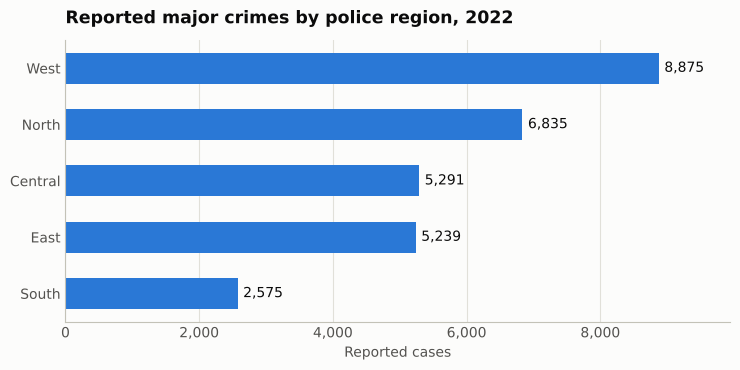

In [14]:
s = regions_only[2022].sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
bars = ax.barh(s.index, s.values, color=BLUE, height=0.55)
ax.bar_label(bars, labels=[f"{v:,.0f}" for v in s.values], padding=4, color=INK)
ax.set_title("Reported major crimes by police region, 2022")
ax.set_xlabel("Reported cases"); ax.set_xlim(0, s.max() * 1.12)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
finish(fig, ax, "1_region_ranking_2022.png", "x")

### Chart 2 — Total reported crimes by region, 2013–2022

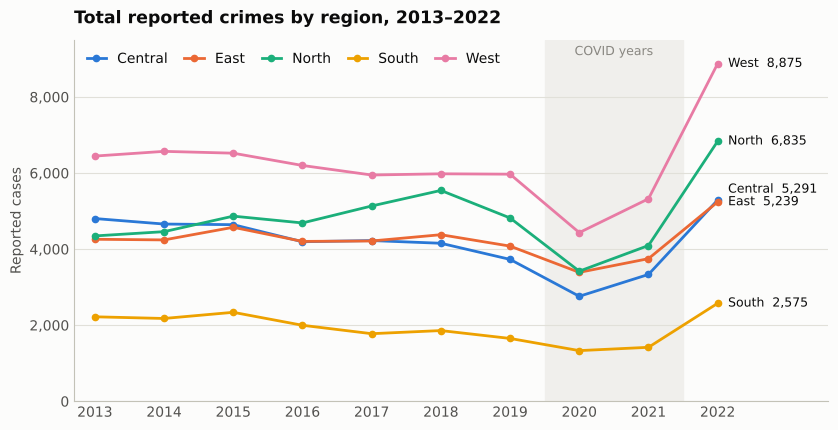

In [15]:
years = [c for c in a1.columns if isinstance(c, (int, np.integer))]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.axvspan(2019.5, 2021.5, color="#f0efec", zorder=0)
ax.text(2020.5, 9350, "COVID years", ha="center", va="top", color=MUTED, fontsize=9)
ends = []
for r in regions_only.index:
    ax.plot(years, regions_only.loc[r, years], color=REGION_COLOR[r], lw=2, marker="o", ms=4.5, label=r)
    ends.append([r, float(regions_only.loc[r, 2022])])
ends.sort(key=lambda e: e[1])                      # nudge end labels apart so they never overlap
for i in range(1, len(ends)):
    ends[i].append(max(ends[i][1], ends[i - 1][-1] + 330))
ends[0].append(ends[0][1])
for r, y, ypos in ends:
    ax.text(2022.15, ypos, f"{r}  {y:,.0f}", va="center", color=INK, fontsize=9)
ax.set_title("Total reported crimes by region, 2013–2022")
ax.set_ylabel("Reported cases"); ax.set_xticks(years); ax.set_xlim(2012.7, 2023.6); ax.set_ylim(0, 9500)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.legend(ncol=5, loc="upper left", bbox_to_anchor=(0, 1.0), handlelength=1.4, columnspacing=1.2)
finish(fig, ax, "2_region_trend_2013_2022.png", "y")

### Chart 3 — Change in reported cases by crime head, 2013 to 2022

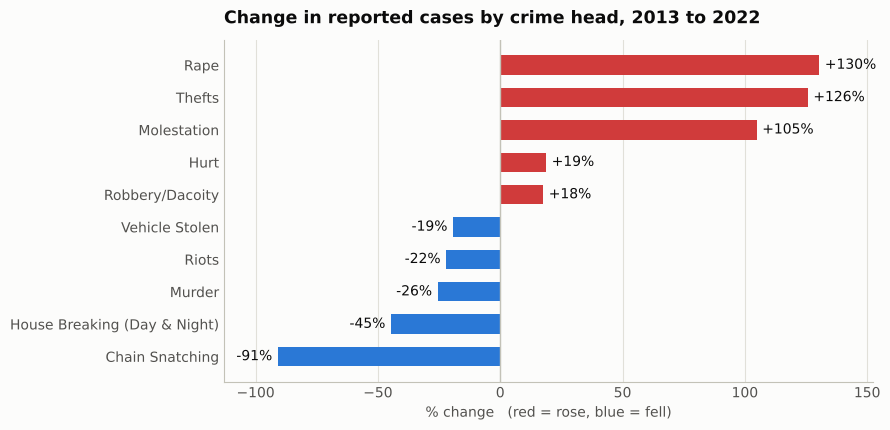

In [16]:
s = (heads_only["% Change"] * 100).sort_values()
fig, ax = plt.subplots(figsize=(9, 4.4))
bars = ax.barh(s.index, s.values, color=[RED if v > 0 else BLUE for v in s.values], height=0.6)
ax.bar_label(bars, labels=[f"{v:+.0f}%" for v in s.values], padding=4, color=INK)
ax.axvline(0, color=AXIS, lw=1)
ax.set_title("Change in reported cases by crime head, 2013 to 2022")
ax.set_xlim(s.min() - 22, s.max() + 22); ax.set_xlabel("% change   (red = rose, blue = fell)")
finish(fig, ax, "3_offence_change.png", "x")

### Chart 4 — Detection rate, 12 highest-volume crime heads, 2023

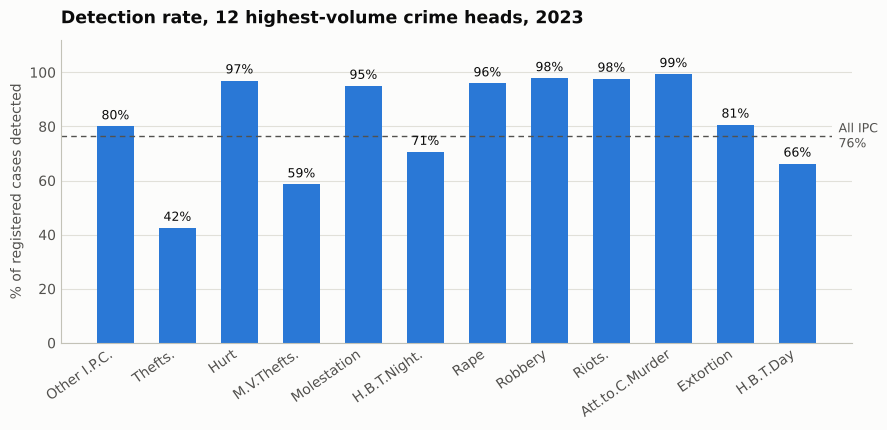

In [17]:
s = a4.head(12)["2023 Detection Rate"] * 100
fig, ax = plt.subplots(figsize=(9, 4.4))
bars = ax.bar(s.index, s.values, color=BLUE, width=0.6)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in s.values], padding=3, color=INK, fontsize=9)
ax.axhline(ipc_rate_2023 * 100, color=INK2, lw=1, ls=(0, (4, 3)))
ax.text(11.6, ipc_rate_2023 * 100, f" All IPC\n {ipc_rate_2023:.0%}", ha="left", va="center", color=INK2, fontsize=9,
        bbox=dict(facecolor=SURFACE, edgecolor="none", pad=1.5))
ax.set_title("Detection rate, 12 highest-volume crime heads, 2023")
ax.set_ylabel("% of registered cases detected"); ax.set_ylim(0, 112)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
finish(fig, ax, "4_detection_rate_2023.png", "y")

### Chart 5 — Cybercrime: registered vs detected by type, 2023

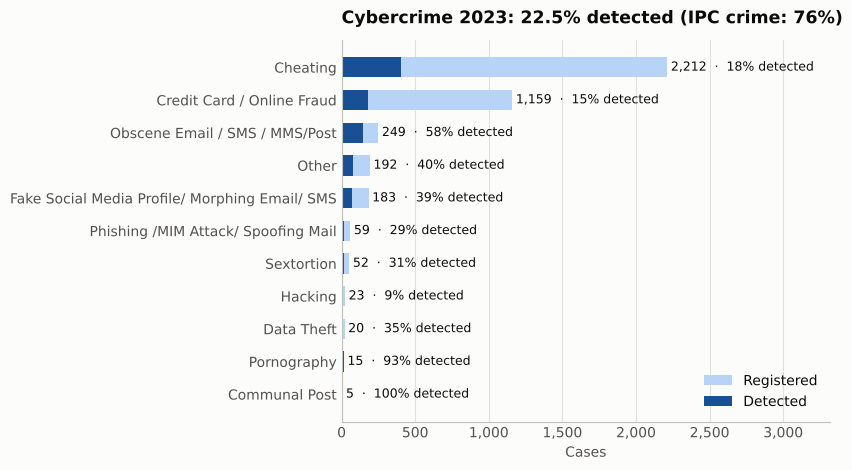

In [18]:
c = main[main.Registered > 0].sort_values("Registered")
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(c["Crime Head"], c.Registered, color="#b7d3f6", height=0.62, label="Registered")
bars = ax.barh(c["Crime Head"], c.Detected, color="#184f95", height=0.62, label="Detected")
for y, (reg, rate) in enumerate(zip(c.Registered, c["Detection Rate"])):
    ax.text(reg + 25, y, f"{reg:,}  ·  {rate:.0%} detected", va="center", color=INK, fontsize=9)
ax.set_title(f"Cybercrime 2023: {cyber_rate_2023:.1%} detected (IPC crime: {ipc_rate_2023:.0%})")
ax.set_xlabel("Cases"); ax.set_xlim(0, c.Registered.max() * 1.5)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.legend(loc="lower right")
finish(fig, ax, "5_cybercrime_2023.png", "x")

### Chart 6 — Crimes against women: registered cases, 2022 vs 2023

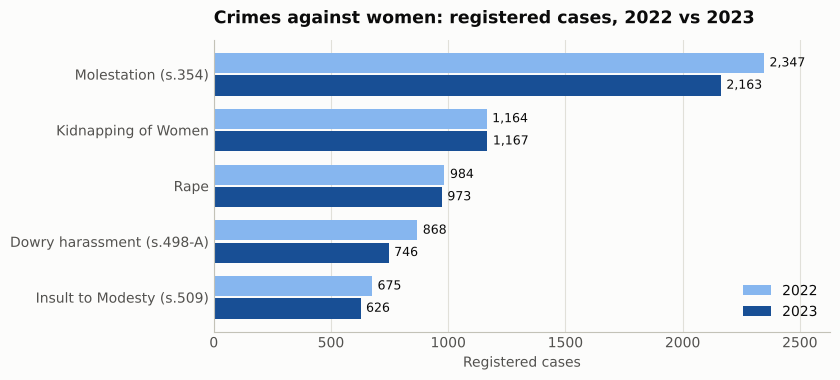

In [19]:
pick = women[(women["Sub-head"] == "TOTAL") & (women.Category != "Acid Attack (s.326A)")]
pick = pd.concat([pick, women[(women.Category == "Dowry") & (women["Sub-head"] == "Harassment (s.498-A)")]
                 .assign(Category="Dowry harassment (s.498-A)")])
p = pick.pivot(index="Category", columns="Year", values="Registered").astype(int).sort_values(2023)
y = np.arange(len(p))
fig, ax = plt.subplots(figsize=(8.5, 3.9))
b1 = ax.barh(y + 0.2, p[2022], height=0.36, color="#86b6ef", label="2022")
b2 = ax.barh(y - 0.2, p[2023], height=0.36, color="#184f95", label="2023")
for b in (b1, b2):
    ax.bar_label(b, labels=[f"{v:,.0f}" for v in b.datavalues], padding=4, color=INK, fontsize=9)
ax.set_yticks(y, p.index); ax.set_xlim(0, p.values.max() * 1.12)
ax.set_title("Crimes against women: registered cases, 2022 vs 2023"); ax.set_xlabel("Registered cases")
ax.legend(loc="lower right")
finish(fig, ax, "6_crimes_against_women.png", "x")

### Dashboard — the four core charts on one page

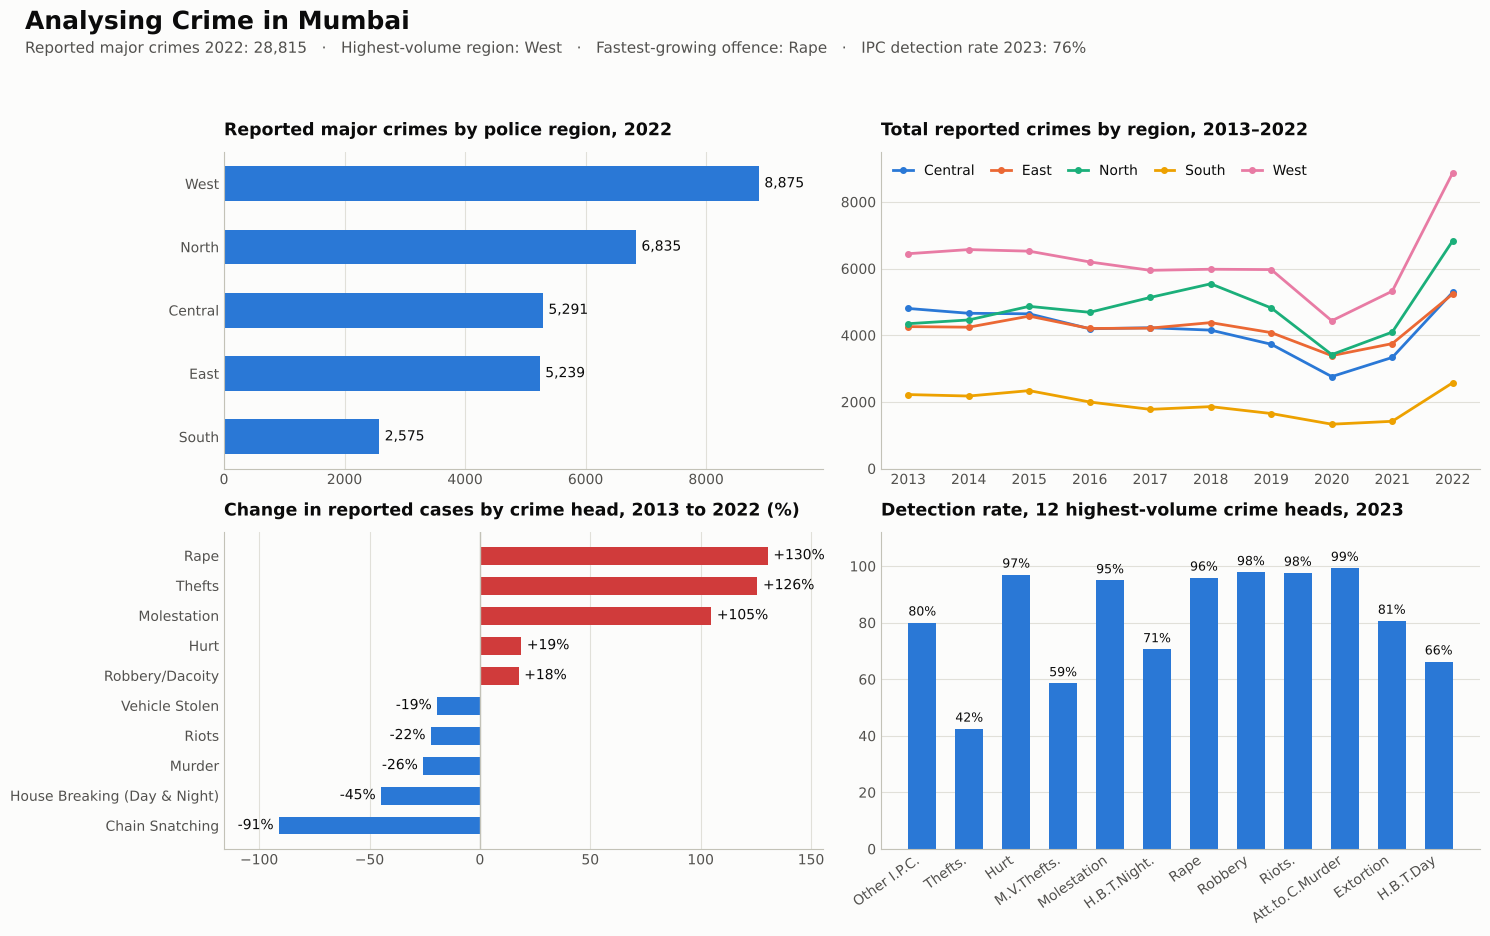

In [20]:
fig, axs = plt.subplots(2, 2, figsize=(15, 9.5))
fig.suptitle("Analysing Crime in Mumbai", x=0.02, ha="left", fontsize=18, fontweight="bold")
fig.text(0.02, 0.935,
         f"Reported major crimes 2022: {int(a1.loc['Mumbai total', 2022]):,}   ·   Highest-volume region: {regions_only[2022].idxmax()}"
         f"   ·   Fastest-growing offence: {heads_only['% Change'].idxmax()}   ·   IPC detection rate 2023: {ipc_rate_2023:.0%}",
         color=INK2, fontsize=11)

ax = axs[0, 0]; s = regions_only[2022].sort_values()
ax.bar_label(ax.barh(s.index, s.values, color=BLUE, height=0.55), labels=[f"{v:,.0f}" for v in s.values], padding=4)
ax.set_title("Reported major crimes by police region, 2022"); ax.set_xlim(0, s.max() * 1.12); ax.grid(axis="y", visible=False)

ax = axs[0, 1]
for r in regions_only.index:
    ax.plot(years, regions_only.loc[r, years], color=REGION_COLOR[r], lw=2, marker="o", ms=4, label=r)
ax.set_title("Total reported crimes by region, 2013–2022"); ax.set_xticks(years); ax.set_ylim(0, 9500)
ax.legend(ncol=5, loc="upper left", handlelength=1.4, columnspacing=1.2); ax.grid(axis="x", visible=False)

ax = axs[1, 0]; s = (heads_only["% Change"] * 100).sort_values()
ax.bar_label(ax.barh(s.index, s.values, color=[RED if v > 0 else BLUE for v in s.values], height=0.6),
             labels=[f"{v:+.0f}%" for v in s.values], padding=4)
ax.axvline(0, color=AXIS, lw=1); ax.set_xlim(s.min() - 25, s.max() + 25)
ax.set_title("Change in reported cases by crime head, 2013 to 2022 (%)"); ax.grid(axis="y", visible=False)

ax = axs[1, 1]; s = a4.head(12)["2023 Detection Rate"] * 100
ax.bar_label(ax.bar(s.index, s.values, color=BLUE, width=0.6), labels=[f"{v:.0f}%" for v in s.values], padding=3, fontsize=9)
ax.set_title("Detection rate, 12 highest-volume crime heads, 2023"); ax.set_ylim(0, 112)
plt.setp(ax.get_xticklabels(), rotation=35, ha="right"); ax.grid(axis="x", visible=False)

for ax in axs.flat:
    ax.tick_params(length=0)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig(OUT / "dashboard.png", dpi=170)
plt.show()

## 5. Validation
Citywide change recomputed from the region tables, compared with Praja's own published summary figures.

             Our figure (%)  Praja published (%)  Match
Rape                  130.4                  130   True
Thefts                125.7                  126   True
Molestation           104.8                  105   True 

Murder 2022, summed across regions: 128 (matches the offence-mix table)


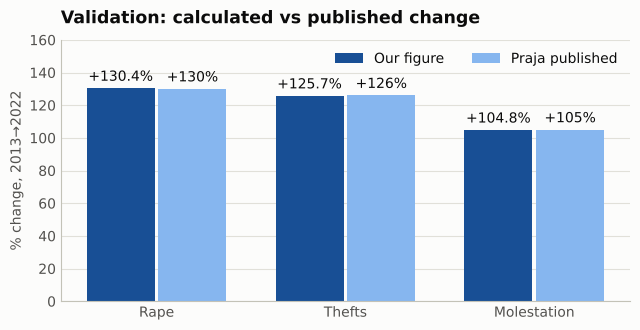

In [21]:
PUBLISHED = {"Rape": 130, "Thefts": 126, "Molestation": 105}
val = pd.DataFrame({"Our figure (%)": (a2.loc[list(PUBLISHED), "% Change"] * 100).round(1),
                    "Praja published (%)": pd.Series(PUBLISHED)})
val["Match"] = val["Our figure (%)"].round(0) == val["Praja published (%)"]
assert val.Match.all()

# second check: murder summed by region equals the citywide figure worked out on another table
assert a3.loc["Murder", "City Total"] == a2.loc["Murder", 2022]
print(val, f"\n\nMurder 2022, summed across regions: {int(a3.loc['Murder', 'City Total'])} (matches the offence-mix table)")

fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = np.arange(len(val))
b1 = ax.bar(x - 0.19, val["Our figure (%)"], width=0.36, color="#184f95", label="Our figure")
b2 = ax.bar(x + 0.19, val["Praja published (%)"], width=0.36, color="#86b6ef", label="Praja published")
ax.bar_label(b1, fmt="+%.1f%%", padding=3); ax.bar_label(b2, fmt="+%.0f%%", padding=3)
ax.set_xticks(x, val.index); ax.set_ylim(0, 160); ax.set_ylabel("% change, 2013→2022")
ax.set_title("Validation: calculated vs published change"); ax.legend(loc="upper right", ncol=2)
finish(fig, ax, "7_validation.png", "y")

## 6. Export the cleaned workbook

In [22]:
with pd.ExcelWriter(OUT / "Mumbai_Crime_Analysis_Python.xlsx", engine="openpyxl") as xw:
    kpi.rename("Value").to_frame().to_excel(xw, sheet_name="Headline_Figures")
    a1.to_excel(xw, sheet_name="A1_Hotspots")
    a2.to_excel(xw, sheet_name="A2_Offence_Mix")
    a3.to_excel(xw, sheet_name="A3_Region_Profile")
    a4.to_excel(xw, sheet_name="A4_Detection")
    val.to_excel(xw, sheet_name="Validation")
    for df, name in [(region, "Region_Crimes"), (rail, "Railway_Crimes"), (staff, "Police_Personnel"),
                     (zones, "Region_Zones"), (ipc, "IPC_Crimes"), (cyber, "Cyber_Crimes"), (women, "Crimes_vs_Women")]:
        df.to_excel(xw, sheet_name=name, index=False)
    for ws in xw.book.worksheets:                      # readable column widths
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = min(48, max(len(str(c.value or "")) for c in col) + 2)
print("Saved:", OUT / "Mumbai_Crime_Analysis_Python.xlsx")

Saved: outputs/Mumbai_Crime_Analysis_Python.xlsx


## Appendix — screening the rejected Kaggle dataset (optional)
Runs only if you place `crime_dataset_india.csv` in `data/raw/`. It reproduces the first screening
test from the report: are Mumbai's crime types suspiciously evenly distributed?

In [23]:
kaggle = RAW / "crime_dataset_india.csv"
if kaggle.exists():
    from scipy.stats import chisquare
    k = pd.read_csv(kaggle)
    mum = k[k["City"].str.strip().str.lower() == "mumbai"]
    counts = mum["Crime Description"].value_counts()
    stat, p = chisquare(counts)                       # H0: every crime type is equally likely
    print(f"{len(k):,} rows | Mumbai rows: {len(mum):,} | crime types: {len(counts)} | range {counts.min()}–{counts.max()}")
    print(f"Chi-square vs flat distribution: p = {p:.2f}  (a high p means the counts look uniformly random)")
    print("Location columns available:", [c for c in k.columns if any(t in c.lower() for t in ("city", "ward", "zone", "station"))])
else:
    print("crime_dataset_india.csv not found — skipping the screening appendix.")

crime_dataset_india.csv not found — skipping the screening appendix.
